In [3]:
import numpy as np
import pandas as pd
import rasterio
import rioxarray
import matplotlib.pyplot as plt
from rasterio.crs import CRS
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import Window, from_bounds
from rasterio.transform import array_bounds
import pyproj

from pathlib import Path
root = Path.cwd()

In [2]:
model = 'three_seasons'
import numpy as np, rioxarray
from scipy.ndimage import binary_dilation

cl = rioxarray.open_rasterio(root / 'model_outputs' / 'residuals' / model / f'{model}_lisa_clusters_100m.tif', masked=True).squeeze('band', drop=True).values
near_hh = binary_dilation(cl == 1, iterations=2)     # within 2 cells of a High-High cluster
near_ll = binary_dilation(cl == 3, iterations=2)
for code, name in ((4, 'High-Low'), (2, 'Low-High')):
    m = cl == code
    print(f'{name}: {m.sum():,} cells ({m.sum() / np.isfinite(cl).sum():.1%}); '
          f'{(m & near_hh).sum() / m.sum():.0%} near HH, {(m & near_ll).sum() / m.sum():.0%} near LL')

High-Low: 239 cells (0.3%); 1% near HH, 87% near LL
Low-High: 310 cells (0.4%); 92% near HH, 2% near LL


In [2]:
landcover_path = 'D:/lidar/landcover_nyc_2021_6in.tif'
chm_path = 'D:/lidar/uchmbt_raster_1p64ft_mosaic.tif'
template_path = root / 'data' / 'nyc21' / 'nyc21_tree_canopy_lidar.tif'                 # defines the 10 m grid
OUT_10M = root / 'data' / 'nyc21' / 'nyc21_landcover_height_fractions_10m.tif'

M_TO_FT = 3.28084
INF = np.inf

# (name, land-cover code, min height m, max height m): a 0.5 m cell belongs to a class if its land-cover
# code matches and min <= height < max. Classes with (-INF, INF) do not use the CHM.
CLASSES = [
    ('tree_under_2.5m',     1, -INF, 2.5),    # tree canopy in land cover but low in the CHM (product mismatch)
    ('tree_2.5_5m',         1,  2.5, 5.0),    # short trees
    ('tree_5m_plus',        1,  5.0, INF),    # tall trees
    ('lawn',                2, -INF, 0.5),
    ('shrub',               2,  0.5, 2.5),
    ('grass_shrub_2.5m_plus', 2, 2.5, INF),   # mismatch (e.g. overhanging canopy); usually small
    ('bare_soil',           3, -INF, INF),
    ('water',               4, -INF, INF),
    ('building_under_15m',  5, -INF, 15.0),   # up to ~4 storeys
    ('building_15m_plus',   5, 15.0, INF),    # tall enough to cast long shadows
    ('road',                6, -INF, INF),
    ('other_impervious',    7, -INF, INF),
    ('railroad',            8, -INF, INF),
]
NAMES = [c[0] for c in CLASSES]

In [3]:
def _horizontal_crs(crs):
    """Horizontal part of a compound (horizontal + vertical) CRS; other CRSs unchanged."""
    try:
        import pyproj
        pc = pyproj.CRS.from_wkt(crs.to_wkt())
        if pc.is_compound:
            return CRS.from_wkt(pc.sub_crs_list[0].to_wkt())
    except ImportError:
        pass
    return crs

In [21]:
chm_units = 'ft'
with rasterio.open(template_path) as tmpl, rasterio.open(chm_path) as chm, rasterio.open(landcover_path) as lc:
    chm_crs = _horizontal_crs(chm.crs)
    print(chm_crs)
    lc_crs = _horizontal_crs(lc.crs)
    scale, offset = (chm.scales[0] or 1.0), (chm.offsets[0] or 0.0)
    lc_nodata = lc.nodata if lc.nodata is not None else 0
    print(f'CHM crs={chm_crs.to_string()} scale={scale} offset={offset} units={chm_units}; '
            f'land cover crs={lc_crs.to_string()} nodata={lc_nodata}')
    print(chm.nodata)

EPSG:6539
CHM crs=EPSG:6539 scale=0.01 offset=0.0 units=ft; land cover crs=EPSG:2263 nodata=0.0
-2147483648.0


In [ ]:
## test that all transforms work properly
with rasterio.open(template_path) as tmpl, rasterio.open(chm_path) as chm, rasterio.open(landcover_path) as lc:
    print('template:', tmpl.crs)
    print('CHM:     ', chm.crs, '-> horizontal:', _horizontal_crs(chm.crs))
    print('land cover:', lc.crs, '-> horizontal:', _horizontal_crs(lc.crs))
    b = tmpl.bounds
    print('template bounds:', b)
    print('to CHM CRS:', transform_bounds(tmpl.crs, _horizontal_crs(chm.crs), *b, densify_pts=21))

chm_test = transform_bounds(tmpl.crs, _horizontal_crs(chm.crs), *b, densify_pts=21)
assert all(np.isfinite(chm_test)), 'transform from template crs to chm crs failed'
t = pyproj.Transformer.from_crs(tmpl.crs.to_wkt(), _horizontal_crs(chm.crs).to_wkt(), always_xy=True)
print(t.description)
print(t.transform(585000, 4510000))          # a point in NYC; should give finite State Plane coordinates

template: EPSG:26918
CHM:      COMPD_CS["NAD83(2011) / New York Long Island (ftUS) + NAVD88 height (ftUS) - US Geoid Model of 2018",PROJCS["NAD83(2011) / New York Long Island (ftUS)",GEOGCS["NAD83(2011)",DATUM["NAD83_National_Spatial_Reference_System_2011",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1116"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","6318"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",40.1666666666667],PARAMETER["central_meridian",-74],PARAMETER["standard_parallel_1",41.0333333333333],PARAMETER["standard_parallel_2",40.6666666666667],PARAMETER["false_easting",984250],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","6539"]],VERT_CS["NAVD88 height (ftUS)",VERT_DATUM["North American Vertical Datum 1988",2005,AUTHORIT

In [ ]:
landcover_height_fractions(landcover_path=landcover_path,chm_path=chm_path,template_path=template_path,out_path=OUT_10M,chm_units='ft')

In [ ]:
def landcover_height_fractions(landcover_path, chm_path, template_path, out_path=OUT_10M,
                               chm_units='ft', tile=128, lc_crs=None, chm_crs=None, classes=CLASSES):
    """Write a GeoTIFF on the 10 m template grid: one band per class (fraction 0-1) + a coverage band
    (share of the 10 m pixel with a valid class). Fractions sum to 1 where coverage > 0.

    chm_units: vertical units of the CHM ('ft' or 'm'); any scale/offset in the file is applied.
    tile:      tile size in 10 m pixels (128 -> 1.28 km tiles; the 15 cm land cover of one tile is ~73M cells).
    """
    to_m = 1 / M_TO_FT if chm_units == 'ft' else 1.0
    with rasterio.open(template_path) as tmpl, rasterio.open(chm_path) as chm, rasterio.open(landcover_path) as lc:
        chm_crs = CRS.from_user_input(chm_crs) if chm_crs else _horizontal_crs(chm.crs)
        lc_crs = CRS.from_user_input(lc_crs) if lc_crs else _horizontal_crs(lc.crs)
        scale, offset = (chm.scales[0] or 1.0), (chm.offsets[0] or 0.0)
        lc_nodata = lc.nodata if lc.nodata is not None else 0
        print(f'CHM crs={chm_crs.to_string()} scale={scale} offset={offset} units={chm_units}; '
              f'land cover crs={lc_crs.to_string()} nodata={lc_nodata}')

        profile = tmpl.profile.copy()
        profile.update(count=len(classes) + 1, dtype='float32', nodata=np.nan, compress='lzw',
                       tiled=True, blockxsize=256, blockysize=256)
        with rasterio.open(out_path, 'w', **profile) as dst:
            for i, name in enumerate([c[0] for c in classes] + ['coverage'], start=1):
                dst.set_band_description(i, name)

            n_tiles = int(np.ceil(tmpl.height / tile) * np.ceil(tmpl.width / tile))
            k = 0
            for row0 in range(0, tmpl.height, tile):
                for col0 in range(0, tmpl.width, tile):
                    k += 1
                    win = Window(col0, row0, min(tile, tmpl.width - col0), min(tile, tmpl.height - row0))
                    tf, shape = tmpl.window_transform(win), (int(win.height), int(win.width))
                    out = np.full((len(classes) + 1,) + shape, np.nan, dtype='float32')

                    # find the 0.5 m CHM cells covering this tile (+ small buffer)

                    ### bounding box of window in template crs
                    b = array_bounds(shape[0], shape[1], tf) 
                    if chm_crs != tmpl.crs: ## convert bounding box to chm crs if necessary
                        b = transform_bounds(tmpl.crs, chm_crs, *b, densify_pts=21)
                    buf = 2 * max(abs(chm.res[0]), abs(chm.res[1])) ## add buffer

                    # get row/columns from bounding box coordinates, use chm transform
                    cwin = from_bounds(b[0] - buf, b[1] - buf, b[2] + buf, b[3] + buf, chm.transform) 
                    # round to avoid fractions of pixels
                    cwin = cwin.round_offsets().round_lengths()
                    # if window is fully outside bounds of chm, continue without writing
                    if (cwin.col_off >= chm.width or cwin.row_off >= chm.height or
                            cwin.col_off + cwin.width <= 0 or cwin.row_off + cwin.height <= 0):
                        dst.write(out, window=win); continue
                    ## trim the window if it partially falls outside bounds of chm
                    cwin = cwin.intersection(Window(0, 0, chm.width, chm.height))
                    # get the transform for this window specifically (needed later for reprojection)
                    ctf = chm.window_transform(cwin)
                    ## read pixels in this window, mask no data values
                    h = chm.read(1, window=cwin, masked=True).astype('float32').filled(np.nan)
                    ## apply scale and offset, set small negatives to 0, convert ft to meters
                    h = np.maximum(h * scale + offset, 0) * to_m               

                    # get land cover category that mostly covers each 0.5 m CHM cell in this window
                    ## bounding coordinates of this window in chm crs
                    cb = array_bounds(h.shape[0], h.shape[1], ctf)
                    ## transform to landcover crs if necessary
                    if lc_crs != chm_crs:
                        cb = transform_bounds(chm_crs, lc_crs, *cb, densify_pts=21)
                    lbuf = 4 * max(abs(lc.res[0]), abs(lc.res[1]))
                    ## get row/cols from bounding coordinates
                    lwin = from_bounds(cb[0] - lbuf, cb[1] - lbuf, cb[2] + lbuf, cb[3] + lbuf, lc.transform)
                    ## round and get intersection of this window and the landcover raster
                    lwin = lwin.round_offsets().round_lengths().intersection(Window(0, 0, lc.width, lc.height))
                    ## read pixels in this window
                    lc_src = lc.read(1, window=lwin)
                    lc05 = np.zeros(h.shape, dtype=lc_src.dtype)
                    ## reproject landcover using mode resampling; each 0.5 m pixel is assigned the most common landcover category present
                    reproject(lc_src, lc05, src_transform=lc.window_transform(lwin), src_crs=lc_crs,
                              src_nodata=lc_nodata, dst_transform=ctf, dst_crs=chm_crs, dst_nodata=0,
                              resampling=Resampling.mode)

                    # combine landcover class and height to assign final classes to 0.5 m pixels. 
                    # cells without a land-cover code, or without a height when the class needs one, are invalid
                    cls = np.full(h.shape, -1, dtype=np.int16)
                    for j, (_, code, hmin, hmax) in enumerate(classes):
                        uses_h = np.isfinite(hmin) or np.isfinite(hmax)
                        m = lc05 == code
                        if uses_h:
                            m &= np.isfinite(h) & (h >= hmin) & (h < hmax)
                        cls[m] = j
                    valid = cls >= 0

                    def to_10m(arr):
                        d = np.full(shape, np.nan, dtype='float32')
                        reproject(arr, d, src_transform=ctf, src_crs=chm_crs, src_nodata=np.nan,
                                  dst_transform=tf, dst_crs=tmpl.crs, dst_nodata=np.nan,
                                  resampling=Resampling.average)
                        return d
                    # reproject 0.5 m to 10m using average resampling
                    for j in range(len(classes)):
                        out[j] = to_10m(np.where(valid, (cls == j).astype('float32'), np.nan))
                    # coverage: share of the 10 m pixel that has a valid class (NaN source cells count as 0)
                    out[-1] = to_10m(valid.astype('float32'))
                    dst.write(out, window=win)
                    if k % 50 == 0 or k == n_tiles:
                        print(f'  tile {k}/{n_tiles}')
    print(f'Wrote {out_path}')

In [9]:
from affine import Affine

def _coarse_coords(src, factor, nx, ny):
    tf = src.rio.transform()
    new_tf = tf * Affine.scale(factor)
    x = new_tf.c + (np.arange(nx) + 0.5) * new_tf.a
    y = new_tf.f + (np.arange(ny) + 0.5) * new_tf.e
    return x, y, new_tf

def load_valid(pred_path, lidar_path):
    """NaN wherever either raster is invalid."""
    pred = rioxarray.open_rasterio(pred_path, masked=True).squeeze('band', drop=True)
    lidar = rioxarray.open_rasterio(lidar_path, masked=True).squeeze('band', drop=True)
    assert pred.shape == lidar.shape and pred.rio.transform().almost_equals(lidar.rio.transform()), \
        'prediction and lidar rasters are not on the same grid'
    valid = pred.notnull() & lidar.notnull()
    
    return valid

def cell_fractions(fractions_10m_path, model, cell_size=100, min_coverage=0.75, res=10):
    """Mean class fractions per coarse cell, over the 10 m pixels that are valid for the LISA analysis
    (`valid`, e.g. resid.notnull()) AND have land-cover data. Returns a DataFrame indexed by (y, x)."""
    pred_path = root / 'model_outputs' / model / f'nyc21_canopy_from_nyc21_{model}_OOF_model.tif'
    lidar_path = root / 'data' / 'nyc21' / 'nyc21_tree_canopy_lidar.tif'
    valid = load_valid(pred_path,lidar_path)

    fr = rioxarray.open_rasterio(fractions_10m_path, masked=True)
    names = list(fr.attrs.get('long_name', NAMES + ['coverage']))
    fr = fr.assign_coords(band=names)
    assert fr.rio.transform().almost_equals(valid.rio.transform()) and fr.shape[1:] == valid.shape, \
        'fractions raster is not on the model grid'
    ok = valid & fr.sel(band=names[0]).notnull()
    f = int(cell_size // res)
    kw = dict(x=f, y=f, boundary='pad')
    n = ok.astype('float32').coarsen(**kw).sum()
    keep = n >= min_coverage * f * f
    x, y, _ = _coarse_coords(valid, f, n.sizes['x'], n.sizes['y'])
    cols = {}
    for nm in names[:-1]:
        s = fr.sel(band=nm).where(ok).fillna(0).coarsen(**kw).sum()
        cols[nm] = (s / n).where(keep).assign_coords(x=x, y=y).to_series()
    return pd.DataFrame(cols).dropna(how='all')

In [23]:
model = 'summer_fall'
fractions = cell_fractions(fractions_10m_path=OUT_10M,model=model,cell_size=100)

In [14]:
def _canopy_bin(canopy, width=10):
    return np.clip(np.floor(canopy / width), 0, int(100 / width) - 1).astype(int)


def compare_clusters(model, fractions, cluster_col='lisa_label',
                     clusters=('High-High', 'Low-Low'), reference='Not significant',
                     canopy_bin_width=10, block_cells=10, n_boot=1000, seed=0):
    """Mean class fractions per cluster type vs. canopy-matched non-significant cells.

    local_stats: DataFrame with x, y and cluster_col (e.g. the *_local_stats_100m.csv from residual_hotspots)
    fractions:   output of cell_fractions() (index y, x)
    cell_canopy: mean lidar canopy % per 100 m cell (DataArray on the same grid)
    Reference = non-significant cells, reweighted so their canopy distribution (bins of canopy_bin_width)
    matches the cluster's. CIs from resampling 1 km blocks (block_cells x block_cells cells).
    Returns a long table: cluster, class, cluster_mean, reference_mean, diff, ci_low, ci_high (in % of area).
    """
    cell_canopy = rioxarray.open_rasterio(root / 'model_outputs' / 'resamp' / 'resamp_100_nyc21_tree_canopy_lidar.tif')
    local_stats = pd.read_csv(root / 'model_outputs' / 'residuals' / model / f'{model}_local_stats_100m.csv')
    d = local_stats[['x', 'y', cluster_col]].merge(fractions.reset_index(), on=['x', 'y'], how='inner')
    can = cell_canopy.to_series().rename('canopy').reset_index()
    d = d.merge(can, on=['x', 'y'], how='inner').dropna()
    classes = [c for c in fractions.columns]
    F = d[classes].to_numpy() * 100                           # percent of cell area
    cbin = _canopy_bin(d['canopy'].to_numpy(), canopy_bin_width)
    nb = cbin.max() + 1

    # 1 km blocks from cell position
    xs, ys = np.sort(d['x'].unique()), np.sort(d['y'].unique())[::-1]
    step = np.median(np.diff(xs))
    col = np.rint((d['x'] - xs.min()) / step).astype(int)
    row = np.rint((ys.max() - d['y']) / step).astype(int)
    blocks, block_idx = np.unique((row // block_cells) * 100000 + col // block_cells, return_inverse=True)
    rng = np.random.default_rng(seed)
    W = rng.multinomial(len(blocks), np.full(len(blocks), 1 / len(blocks)), size=n_boot)

    ref = (d[cluster_col] == reference).to_numpy()

    def matched(w, grp):
        """Weighted cluster mean, canopy-matched reference mean."""
        wc, wr = w * grp, w * ref
        ref_sum = np.zeros((nb, F.shape[1])); np.add.at(ref_sum, cbin, F * wr[:, None])
        ref_w = np.bincount(cbin, weights=wr, minlength=nb)
        grp_w = np.bincount(cbin, weights=wc, minlength=nb)
        usable = (ref_w > 0) & (grp_w > 0)                     # canopy bins present in both groups
        share = np.where(usable, grp_w, 0) / max(grp_w[usable].sum(), 1e-12)
        ref_mean = (share[usable, None] * ref_sum[usable] / ref_w[usable, None]).sum(0)
        in_usable = usable[cbin] & grp
        cl_mean = (F[in_usable] * w[in_usable, None]).sum(0) / max(w[in_usable].sum(), 1e-12)
        return cl_mean, ref_mean

    rows = []
    for cl in clusters:
        grp = (d[cluster_col] == cl).to_numpy()
        if not grp.any():
            continue
        cm, rm = matched(np.ones(len(d)), grp)
        boots = np.array([np.subtract(*matched(W[i][block_idx].astype(float), grp)) for i in range(n_boot)])
        lo, hi = np.nanquantile(boots, [0.025, 0.975], axis=0)
        for j, c in enumerate(classes):
            rows.append({'cluster': cl, 'class': c, 'n_cells': int(grp.sum()),
                         'cluster_mean': cm[j], 'reference_mean': rm[j], 'diff': cm[j] - rm[j],
                         'ci_low': lo[j], 'ci_high': hi[j]})
    return pd.DataFrame(rows)

In [24]:
## on average, x landcover covers x% of a high-high or low-low cluster
cluster_fracs = compare_clusters(model=model,fractions=fractions)

In [25]:
cluster_fracs.to_csv(root / 'model_outputs' / model / f'cluster_fractions_{model}.csv')

In [11]:
ml = {'Growing_Season': 'growing_season', 'Three Seasons':'three_seasons','Two Seasons':'summer_fall'}

ml.values()

dict_values(['growing_season', 'three_seasons', 'summer_fall'])

In [ ]:

models = ['growing_season', 'three_seasons','summer_fall']
labels = ['Growing Season','Three Seasons', 'Two Seasons']

ml = {'Growing_Season': 'growing_season', 'Three Seasons':'three_seasons','Two Seasons':'summer_fall'}

tables = {l:pd.read_csv(root / 'model_outputs' / m / f'cluster_fractions_{m}.csv') for l,m in ml.items()}

# d = ['tree_under_2.5m', 'grass_shrub_2.5m_plus','water','road','other_impervious','railroad']


In [6]:
tables[0]

,Unnamed: 0,cluster,class,n_cells,cluster_mean,reference_mean,diff,ci_low,ci_high
0,0,High-High,tree_under_2.5m,5161,2.555146,1.988909,0.566236,0.405029,0.713245
1,1,High-High,tree_2.5_5m,5161,4.889061,3.254867,1.634195,1.102809,2.273705
2,2,High-High,tree_5m_plus,5161,24.650968,26.555001,-1.904033,-2.670245,-1.231986
3,3,High-High,lawn,5161,25.962405,13.591934,12.370471,10.337638,14.558393
4,4,High-High,shrub,5161,3.117365,1.282898,1.834466,1.362323,2.424148
5,5,High-High,grass_shrub_2.5m_plus,5161,1.249590,0.821028,0.428562,0.328993,0.529945
6,6,High-High,bare_soil,5161,1.621744,1.020185,0.601559,0.189630,1.128751
7,7,High-High,water,5161,1.831363,1.164561,0.666802,0.229535,1.130390
8,8,High-High,building_under_15m,5161,9.677178,14.717566,-5.040388,-6.103867,-4.050096
9,9,High-High,building_15m_plus,5161,0.397731,3.185058,-2.787327,-3.147966,-2.447945


In [16]:
table_three = pd.read_csv(root / 'model_outputs' / 'three_seasons' / f'cluster_fractions_three_seasons.csv')
table_two = pd.read_csv(root / 'model_outputs' / 'summer_fall' / f'cluster_fractions_summer_fall.csv')
table_growing = pd.read_csv(root / 'model_outputs' / 'growing_season' / f'cluster_fractions_growing_season.csv')

d = ['tree_under_2.5m', 'grass_shrub_2.5m_plus','water','road','other_impervious','railroad']
tables1 = {'Three Seasons Model': table_three,      # each = output of compare_clusters for that model
          'Two Seasons Model': table_two,
          'Growing Season Model': table_growing}
#plot_comparison_models(tables, fname='cluster_landcover_models.png')
tables = {k:t.loc[~t['class'].isin(d)].copy() for k,t in tables1.items()}

In [65]:
cl = 'building_15m_plus'
a = []
for t in [table_three,table_two,table_growing]:
    d = t.loc[(t['cluster']=='Low-Low')&(t['class']==cl)]
    a.append(d)
pd.concat(a)

,Unnamed: 0,cluster,class,n_cells,cluster_mean,reference_mean,diff,ci_low,ci_high
22,22,Low-Low,building_15m_plus,3584,9.106391,3.679611,5.426780,3.460234,7.409994
22,22,Low-Low,building_15m_plus,4619,12.302975,3.497806,8.805169,6.885616,10.592881
22,22,Low-Low,building_15m_plus,5089,14.210013,3.430693,10.779320,8.686297,12.725377


In [71]:
plot_comparison_models(tables, fname='cluster_landcover_models.png',classes=['bare_soil','lawn','shrub','tree_2.5_5m','tree_5m_plus','building_under_15m','building_15m_plus'])

C:\Users\roseh\AppData\Local\Temp\ipykernel_23788\3398273057.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [70]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

LABELS = {'tree_under_2.5m': 'Tree canopy < 2.5 m (mismatch)', 'tree_2.5_5m': 'Short Trees (2.5–5 m)',
          'tree_5m_plus': 'Tall Trees (≥ 5 m)', 'lawn': 'Lawn (< 0.5 m)', 'shrub': 'Shrubs (0.5–2.5 m)',
          'grass_shrub_2.5m_plus': 'Grass/shrub ≥ 2.5 m (mismatch)', 'bare_soil': 'Bare soil', 'water': 'Water',
          'building_under_15m': 'Short Buildings (< 15 m)', 'building_15m_plus': 'Tall Buildings (≥ 15 m)', 'road': 'Roads',
          'other_impervious': 'Other impervious', 'railroad': 'Railroads'}
CLUSTER_TEXT = {'High-High': 'Clustered over-prediction',
                'Low-Low': 'Clustered under-prediction'}
c1 = '#285A48'
c2 = '#8BBB92'
c3 = '#3B9797'
MODEL_COLORS = {'Three Seasons Model': c1, 'Two Seasons Model': c3,
                'Growing Season Model': c2}        
MODEL_MARKERS = ['o', 's', 'D']


def plot_comparison_models(tables, fname=None, title=None, classes=None):
    """tables: {model label: compare_clusters() output}. One panel per cluster type; within each panel,
    one row per land-cover class with a dot + 95% CI per model (offset vertically)."""
    models = list(tables)
    first = tables[models[0]]
    clusters = list(dict.fromkeys(first['cluster']))
    classes = classes or list(dict.fromkeys(first['class']))
    k = len(models)
    step = 0.22                                           # vertical spacing between models within a class row
    offsets = (np.arange(k) - (k - 1) / 2) * step

    fig, axes = plt.subplots(1, len(clusters), figsize=(4.6 * len(clusters), 0.42 * len(classes) + 1.6),
                             sharey=True, sharex=True, squeeze=False)
    ypos = np.arange(len(classes))[::-1]
    for ax, cl in zip(axes[0], clusters):
        ax.axvline(0, color='0.5', lw=0.8)
        for y in ypos[1::2]:                              # light bands to separate class rows
            ax.axhspan(y - 0.5, y + 0.5, color='0.95', zorder=0, lw=0)
        ns = []
        for i, m in enumerate(models):
            t = tables[m]
            t = t[t.cluster == cl].set_index('class').reindex(classes)
            ns.append(f"{int(t['n_cells'].dropna().iloc[0]):,}")
            ax.errorbar(t['diff'], ypos - offsets[i],
                        xerr=[t['diff'] - t['ci_low'], t['ci_high'] - t['diff']],
                        fmt=MODEL_MARKERS[i % len(MODEL_MARKERS)], ms=4.5,
                        color=MODEL_COLORS.get(m, f'C{i}'), elinewidth=1.3, capsize=0)
        #ax.set_title(f"{CLUSTER_TEXT.get(cl, cl)}\n{' / '.join(ns)}", fontsize=9, loc='left')
        ax.set_title(f"{CLUSTER_TEXT.get(cl, cl)}", fontsize=9, loc='left')
        #ax.set_xlabel('Difference in share of cell area (percentage points)\n'
                      #'vs. non-clustered cells with similar canopy', fontsize=8)
        ax.set_xlabel('Difference in Cell Coverage (percentage points)\nclustered cells vs. non-clustered cells', fontsize=8)
        ax.grid(axis='x', alpha=0.3)
        ax.set_ylim(-0.5, len(classes) - 0.5)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    axes[0, 0].set_yticks(ypos)
    axes[0, 0].set_yticklabels([LABELS.get(c, c) for c in classes], fontsize=8)
    axes[0, 0].tick_params(axis='y', length=0)

    handles = [Line2D([], [], color=MODEL_COLORS.get(m, f'C{i}'), marker=MODEL_MARKERS[i % len(MODEL_MARKERS)],
                      ms=5, lw=1.3, label=m) for i, m in enumerate(models)]
    fig.legend(handles=handles, loc='upper center', ncol=k, frameon=False, fontsize=9,
               bbox_to_anchor=(0.55, 1.0 if not title else 0.98))
    if title:
        fig.suptitle(title, fontsize=10, y=1.06)
    plt.tight_layout(rect=(0, 0, 1, 0.965))
    if fname:
        plt.savefig(root / 'figs'/ fname, dpi=300, bbox_inches='tight')
    plt.show()


  

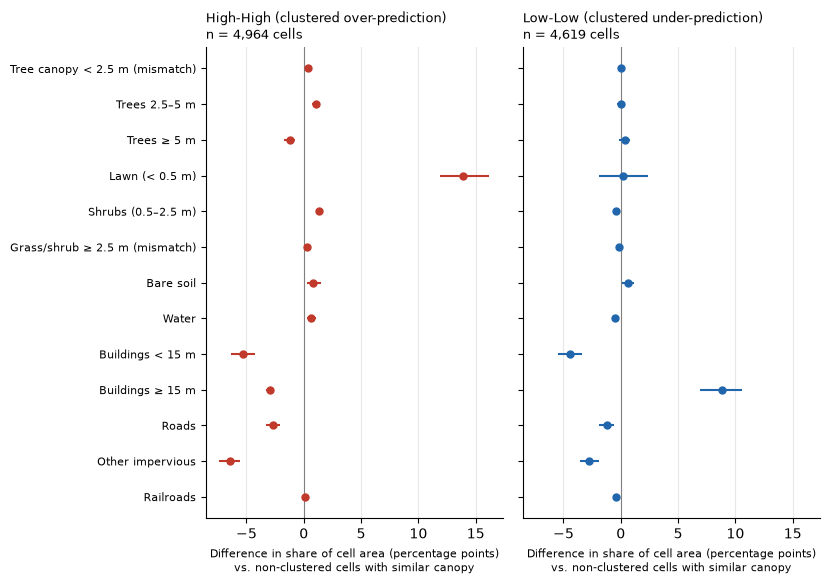

In [30]:
plot_comparison(table=cluster_fracs,fname=None)

In [28]:
LABELS = {'tree_under_2.5m': 'Tree canopy < 2.5 m (mismatch)', 'tree_2.5_5m': 'Trees 2.5–5 m',
          'tree_5m_plus': 'Trees ≥ 5 m', 'lawn': 'Lawn (< 0.5 m)', 'shrub': 'Shrubs (0.5–2.5 m)',
          'grass_shrub_2.5m_plus': 'Grass/shrub ≥ 2.5 m (mismatch)', 'bare_soil': 'Bare soil', 'water': 'Water',
          'building_under_15m': 'Buildings < 15 m', 'building_15m_plus': 'Buildings ≥ 15 m', 'road': 'Roads',
          'other_impervious': 'Other impervious', 'railroad': 'Railroads'}
CLUSTER_COLORS = {'High-High': '#C0392B', 'Low-Low': '#2166AC'}
CLUSTER_TEXT = {'High-High': 'High-High (clustered over-prediction)',
                'Low-Low': 'Low-Low (clustered under-prediction)'}


def plot_comparison(table, fname, title=None):
    """Dot + 95% CI of (cluster − canopy-matched reference) per class, one panel per cluster type."""
    clusters = list(dict.fromkeys(table['cluster']))
    classes = list(dict.fromkeys(table['class']))
    fig, axes = plt.subplots(1, len(clusters), figsize=(4.2 * len(clusters), 0.35 * len(classes) + 1.4),
                             sharey=True, sharex=True, squeeze=False)
    ypos = np.arange(len(classes))[::-1]
    for ax, cl in zip(axes[0], clusters):
        t = table[table.cluster == cl].set_index('class').loc[classes]
        c = CLUSTER_COLORS.get(cl, 'black')
        ax.axvline(0, color='0.5', lw=0.8)
        ax.errorbar(t['diff'], ypos, xerr=[t['diff'] - t['ci_low'], t['ci_high'] - t['diff']],
                    fmt='o', ms=5, color=c, ecolor=c, elinewidth=1.5, capsize=0)
        ax.set_title(f"{CLUSTER_TEXT.get(cl, cl)}\nn = {int(t['n_cells'].iloc[0]):,} cells", fontsize=9, loc='left')
        ax.set_xlabel('Difference in share of cell area (percentage points)\nvs. non-clustered cells with similar canopy',
                      fontsize=8)
        ax.grid(axis='x', alpha=0.3)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    axes[0, 0].set_yticks(ypos)
    axes[0, 0].set_yticklabels([LABELS.get(c, c) for c in classes], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); #plt.savefig(fname, dpi=300, bbox_inches='tight'); plt.close()